# 04 – Sensor trust: noon reports

**Question:** can we trust the daily noon reports, and can they serve as an independent check on the sensors?

The noon reports are written by the crew once a day: drafts, displacement, fuel consumed since the last report, weather by eye (Beaufort, sea state), sea temperature and slip. They matter because:
- the **draft sensors are dead** (DQ-01), so loading condition must come from here;
- **noon fuel** is the only check on the fuel meter that does not come from the ship's automation, and the fuel meter is needed to judge the torquemeter (01 §6i).

Same rules and steps as the other notebooks (see `README.md`).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.path.insert(0, os.path.join("..", "..", "src"))
import trust as T

noon = T.load_noon()
F = T.Findings("04_noon_reports")
w = T.load_wide(["fo_kgh", "me_rpm", "me_tc_rpm_tr", "me_scav_bar", "shaft_kw", "shaft_rpm", "sog_kn", "stw_kn", "heading_deg",
                 "s_sst", "mb_wind_kn", "s_wind_e", "s_wind_n"], name="noon_check2")
mode = T.operating_mode(w)

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 200, "display.max_columns", 30)

def month_axis(ax):
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

# text columns -> numbers (same idea as src/clean_weather_data.py)
noon["slip_pct"] = pd.to_numeric(noon.Slip.str.replace("%:", "", regex=False).str.strip(), errors="coerce")
noon["sea_state"] = pd.to_numeric(noon["Sea State"].str.extract(r"^\s*(\d+)")[0], errors="coerce")
noon["beaufort"] = pd.to_numeric(noon["Wind Force"].str.extract(r"^\s*(\d+)")[0], errors="coerce")
noon["mean_draft"] = (noon["Fwd Draft"] + noon["Aft Draft"]) / 2
noon["trim"] = noon["Aft Draft"] - noon["Fwd Draft"]
print(f"{len(noon)} noon reports, {noon.index.min().date()} – {noon.index.max().date()}")
noon.head(3).T

366 noon reports, 2024-01-01 – 2024-12-31


date,2024-01-01,2024-01-02,2024-01-03
Date,01/01/2024,02/01/2024,03/01/2024
Slip,%: 0,%: 0,%: 0
Fwd Draft,10.19,10.19,10.19
Mid Draft,10.19,10.19,10.19
Aft Draft,10.19,10.19,10.19
Displacement,61500.8,51477.0,41439.1
Air Temp,22,25,25
Bar Pressure,1022,1025,1025
Sea State,02 smooth,02 smooth,02 smooth
Wind Force,02 light breeze,02 light breeze,02 light breeze


## 1. Missing data and fake values

In [2]:
cols = ["Fwd Draft", "Mid Draft", "Aft Draft", "Displacement", "Consumption for Propulsion", "Fuel", "slip_pct",
        "Sea Temp", "beaufort", "sea_state", "Air Temp", "Bar Pressure"]
miss = pd.DataFrame({"missing days": noon[cols].isna().sum(), "zero": (noon[cols].select_dtypes("number") == 0).sum()})
display(miss)
known = mode[mode != "unknown"]                         # moments with GPS speed; the rest of the day is unknown
day_known = (mode != "unknown").groupby(mode.index.normalize()).mean()
d_port = known.groupby(known.index.normalize()).agg(lambda x: x.isin(["port", "anchor", "port, propeller turning"]).mean())
d_port = d_port.where(day_known.reindex(d_port.index) >= 0.5)   # NaN = less than half the day known (e.g. the Sep–Oct logger gap)
nofuel = noon["Consumption for Propulsion"].isna()
dp_nf = d_port.reindex(noon.index[nofuel])
print(f"days without fuel: {nofuel.sum()}; of those mostly in port or at anchor (sensors): {int((dp_nf > 0.5).sum())}, "
      f"mostly at sea: {int((dp_nf <= 0.5).sum())}, unknown (no speed data): {int(dp_nf.isna().sum())}")
print("fuel types:", noon.Fuel.value_counts().to_dict())

,missing days,zero
Aft Draft,0,0.0
Air Temp,0,0.0
Bar Pressure,0,0.0
Consumption for Propulsion,116,0.0
Displacement,0,0.0
Fuel,116,NaN
Fwd Draft,0,0.0
Mid Draft,0,0.0
Sea Temp,0,0.0
beaufort,0,0.0


days without fuel: 116; of those mostly in port or at anchor (sensors): 59, mostly at sea: 47, unknown (no speed data): 10
fuel types: {'LSIFO': 244, 'LSMGO': 6}


## 2. Loading condition: do drafts and displacement agree?

From the particulars, displacement (t, ×1.025) at mean draft: ballast 6.4 m → 37,000 t; heavy ballast 6.9 m → 40,000 t; design 12.2 m → 75,200 t; scantling 14.25 m → 89,100 t. The expected displacement for each reported mean draft is interpolated between these points and compared with the reported displacement.

reported vs expected displacement: median -1.5 %, IQR -2.1 to -0.1 %, 247 days in the draft range of the table; off by more than 10 %: 4 days


,Fwd Draft,Aft Draft,mean_draft,Displacement,disp_expected,disp_err_pct
date,,,,,,
2024-01-02,10.2,10.2,10.2,51477.0,61837.8,-16.8
2024-01-03,10.2,10.2,10.2,41439.1,61837.8,-33.0
2024-07-02,8.4,9.1,8.8,38499.1,52279.4,-26.4
2024-10-04,14.1,14.4,14.2,75017.0,89046.5,-15.8


days with unchanged drafts but displacement change > 3,000 t: 3  (operating mode those days: [np.float64(1.0), np.float64(1.0), np.float64(0.52)] share in port/anchor)


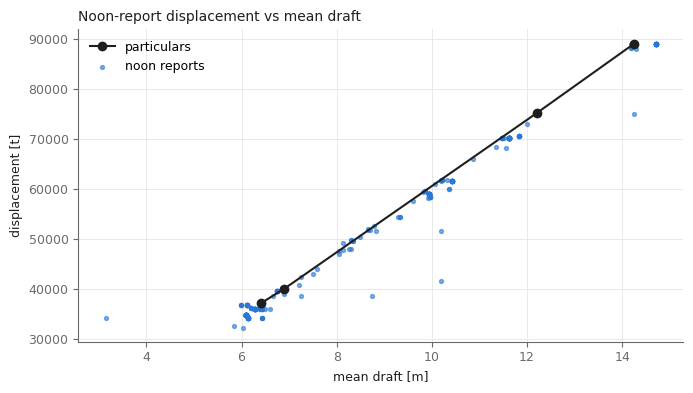

In [3]:
hyd = pd.DataFrame({"T": [6.4, 6.9, 12.2, 14.25], "disp": [36134 * 1.025, 39024 * 1.025, 73346 * 1.025, 86941 * 1.025]})
noon["disp_expected"] = np.interp(noon.mean_draft, hyd["T"], hyd.disp, left=np.nan, right=np.nan)
noon["disp_err_pct"] = 100 * (noon.Displacement / noon.disp_expected - 1)
e = noon.disp_err_pct.dropna()
print(f"reported vs expected displacement: median {e.median():+.1f} %, IQR {e.quantile(.25):+.1f} to {e.quantile(.75):+.1f} %, "
      f"{len(e)} days in the draft range of the table; off by more than 10 %: {(e.abs() > 10).sum()} days")
display(noon.loc[noon.disp_err_pct.abs() > 10, ["Fwd Draft", "Aft Draft", "mean_draft", "Displacement", "disp_expected", "disp_err_pct"]].round(1))

stale = (noon[["Fwd Draft", "Aft Draft"]].diff().abs().sum(axis=1) == 0) & (noon.Displacement.diff().abs() > 3000)
print(f"days with unchanged drafts but displacement change > 3,000 t: {stale.sum()}  "
      f"(operating mode those days: {[round(d_port.get(d, np.nan), 2) for d in noon.index[stale]]} share in port/anchor)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hyd["T"], hyd.disp, color=INK, marker="o", lw=1.5, label="particulars")
ax.scatter(noon.mean_draft, noon.Displacement, s=8, color=BLUE, alpha=0.6, label="noon reports")
ax.set_xlabel("mean draft [m]"); ax.set_ylabel("displacement [t]"); ax.legend(frameon=False)
ax.set_title("Noon-report displacement vs mean draft", loc="left", color=INK)
fig.tight_layout(); plt.show()

### 2b. When does the loading change?

Cargo is loaded and discharged in port. A big change in displacement on a day the sensors say the ship was **sailing** all day is suspicious (or a late report).

32 days with a displacement change above 3,000 t


,change_t,share_of_day_in_port_or_anchor,share_previous_day
date,,,
2024-01-02,-10024.0,1.00,1.00
2024-01-03,-10038.0,1.00,1.00
2024-01-04,-5554.0,0.26,1.00
2024-02-02,6998.0,0.96,0.81
2024-02-03,11574.0,NaN,0.96
2024-02-06,13953.0,1.00,1.00
2024-03-30,-26242.0,1.00,0.79
2024-03-31,-9971.0,0.46,1.00
2024-05-26,-4529.0,0.98,1.00


changes on days fully at sea (today and yesterday): 1; on days with unknown position (no speed data): 11


,change_t,share_of_day_in_port_or_anchor,share_previous_day
date,,,
2024-10-05,13693.0,0.0,0.0


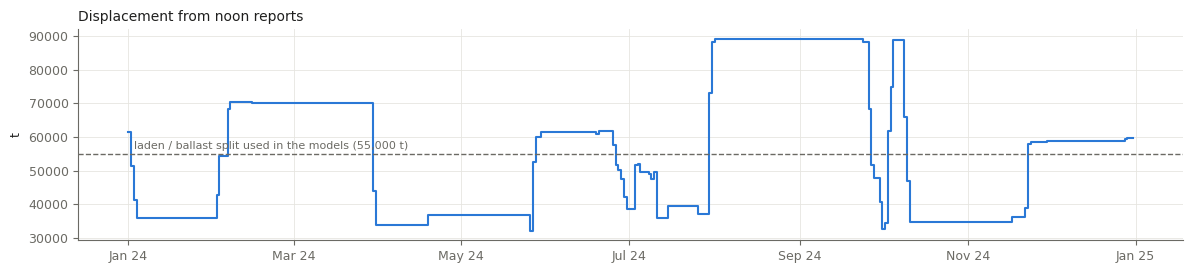

In [4]:
chg = noon.Displacement.diff()
big = chg.abs() > 3000
tab = pd.DataFrame({"change_t": chg[big].round(0), "share_of_day_in_port_or_anchor": d_port.reindex(noon.index[big]).round(2),
                    "share_previous_day": d_port.reindex(noon.index[big] - pd.Timedelta("1D")).values.round(2)})
print(f"{big.sum()} days with a displacement change above 3,000 t")
display(tab)
at_sea = tab[(tab.share_of_day_in_port_or_anchor < 0.1) & (tab.share_previous_day < 0.1)]
unknown_days = tab[tab.share_of_day_in_port_or_anchor.isna() | tab.share_previous_day.isna()]
print(f"changes on days fully at sea (today and yesterday): {len(at_sea)}; on days with unknown position (no speed data): {len(unknown_days)}")
display(at_sea)
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.step(noon.index, noon.Displacement, where="post", color=BLUE, lw=1.5)
ax.axhline(55000, color=MUTED, ls="--", lw=1); ax.text(noon.index[2], 56500, "laden / ballast split used in the models (55,000 t)", color=MUTED, fontsize=8)
ax.set_ylabel("t"); ax.set_title("Displacement from noon reports", loc="left", color=INK); month_axis(ax)
fig.tight_layout(); plt.show()

## 3. Fuel: noon reports vs the fuel meter

Noon fuel ("Consumption for Propulsion", t per day) is compared with the fuel meter (`fo_kgh`) summed over the same day, counting only moments with the engine turning (DQ-13). The noon "day" may not run midnight to midnight, so the meter window is shifted and the best-matching shift is used. Only days with at least 23 h of meter data and more than 5 t of noon fuel.

In [5]:
fuel_t = w.fo_kgh.where(w.me_rpm > 30, 0) * 15 / 3600 / 1000          # t per 15 s, engine turning only
cover_h = w.fo_kgh.notna().astype(float) * 15 / 3600

def daily_meter(shift_h):
    s, c = fuel_t.copy(), cover_h.copy()
    s.index = s.index - pd.Timedelta(hours=shift_h); c.index = c.index - pd.Timedelta(hours=shift_h)
    d = pd.DataFrame({"noon": noon["Consumption for Propulsion"], "meter": s.resample("D").sum(), "hours": c.resample("D").sum()}).dropna()
    return d[(d.hours > 23) & (d.noon > 5)]

scan = pd.DataFrame([{"window ends at (h, UTC)": 24 + sh, "shift_h": sh, "days": len(daily_meter(sh)),
                      "correlation": np.corrcoef(daily_meter(sh).noon, daily_meter(sh).meter)[0, 1]} for sh in range(-18, 7, 3)])
display(scan.round(3))
best = int(scan.loc[scan.correlation.idxmax(), "shift_h"])
fd = daily_meter(best)
fd["ratio"] = fd.meter / fd.noon
print(f"best match: the noon day ends about {24 + best:02d}:00 UTC (correlation {scan.correlation.max():.2f})")

,"window ends at (h, UTC)",shift_h,days,correlation
0,6,-18,221,0.806
1,9,-15,223,0.811
2,12,-12,222,0.804
3,15,-9,221,0.790
4,18,-6,220,0.774
5,21,-3,221,0.749
6,24,0,221,0.715
7,27,3,221,0.679
8,30,6,222,0.648


best match: the noon day ends about 09:00 UTC (correlation 0.81)


,meter / noon (median),IQR low,IQR high,days
1 Jan – 9 Jul,1.013,0.947,1.065,100.0
10 Jul – 23 Sep,1.050,1.000,1.102,67.0
16 Oct – 31 Dec,1.024,0.989,1.179,56.0


,from,to,days,median,change_vs_previous_%
0,2024-01-05,2024-04-14,75,1.026,NaN
1,2024-04-15,2024-04-25,10,0.854,-16.799
2,2024-04-26,2024-12-27,138,1.033,21.008


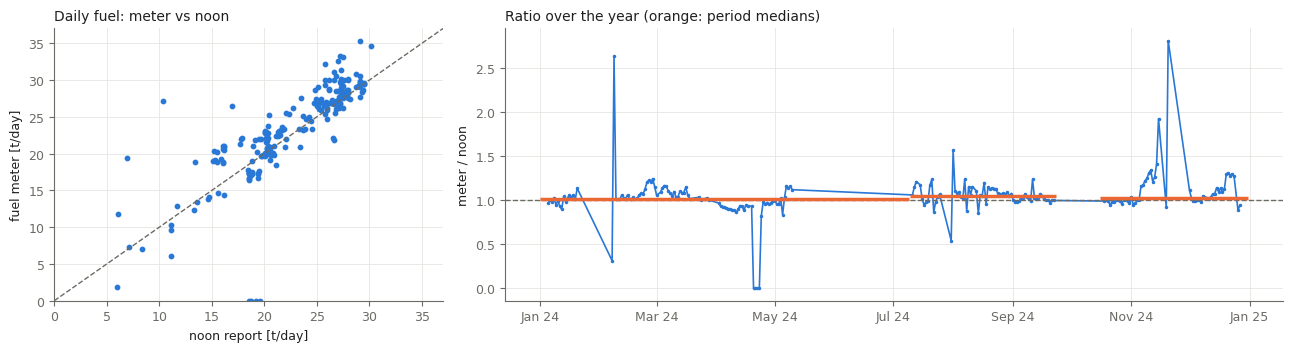

noon fuel values that are whole numbers: 7 % (a crew reading off a tank sounding often rounds; values copied from the meter usually are not)


In [6]:
periods = {"1 Jan – 9 Jul": ("2024-01-01", "2024-07-09"), "10 Jul – 23 Sep": ("2024-07-10", "2024-09-23"),
           "16 Oct – 31 Dec": ("2024-10-16", "2024-12-31")}
fuel_tab = pd.DataFrame({k: {"meter / noon (median)": fd.ratio.loc[a:b].median(), "IQR low": fd.ratio.loc[a:b].quantile(.25),
                             "IQR high": fd.ratio.loc[a:b].quantile(.75), "days": len(fd.loc[a:b])} for k, (a, b) in periods.items()}).T
display(fuel_tab.round(3))
display(T.find_steps(fd.ratio.asfreq("D")).round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2]})
axes[0].scatter(fd.noon, fd.meter, s=10, color=BLUE)
lim = [0, max(fd.noon.max(), fd.meter.max()) * 1.05]
axes[0].plot(lim, lim, color=MUTED, ls="--", lw=1); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("noon report [t/day]"); axes[0].set_ylabel("fuel meter [t/day]")
axes[0].set_title("Daily fuel: meter vs noon", loc="left", color=INK)
axes[1].plot(fd.index, fd.ratio, color=BLUE, lw=1.2, marker=".", ms=3)
axes[1].axhline(1, color=MUTED, ls="--", lw=1)
for name, (a, b) in periods.items():
    axes[1].hlines(fd.ratio.loc[a:b].median(), pd.Timestamp(a), pd.Timestamp(b), color=ORANGE, lw=2.5)
axes[1].set_ylabel("meter / noon"); axes[1].set_title("Ratio over the year (orange: period medians)", loc="left", color=INK)
month_axis(axes[1]); fig.tight_layout(); plt.show()
print(f"noon fuel values that are whole numbers: {100 * (noon['Consumption for Propulsion'].dropna() % 1 == 0).mean():.0f} % "
      "(a crew reading off a tank sounding often rounds; values copied from the meter usually are not)")

### 3b. Is noon fuel an independent check? Test against the engine's air side

If noon fuel were measured independently (tank soundings), it would expose a fuel-meter drift. To test that, power is estimated three ways from engine signals, each fitted on Jan – 9 Jul where the torquemeter is trusted: from **fuel flow + rpm**, from **scavenge air pressure + rpm**, and from **turbocharger speed + rpm**. Scavenge pressure and turbocharger speed are both air-side signals and do not involve the fuel meter.

The estimates are compared **within the same power band**, because the ship runs at lower load in Oct–Dec than in spring and simple ratios (e.g. scavenge pressure ÷ fuel) are distorted by load changes.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
run_ = (mode == "sailing") & (w.me_rpm > 50) & (w.fo_kgh > 300)
fit_ = run_ & (w.index < "2024-07-10") & (w.shaft_kw > 800)
est = {}
for name, cols in {"fuel": ["fo_kgh", "me_rpm"], "scavenge": ["me_scav_bar", "me_rpm"], "turbo": ["me_tc_rpm_tr", "me_rpm"]}.items():
    X = w[cols]; ok = X.notna().all(axis=1)
    mdl = make_pipeline(PolynomialFeatures(2), LinearRegression()).fit(X[fit_ & ok], w.shaft_kw[fit_ & ok])
    p = pd.Series(np.nan, index=w.index); sel = run_ & ok; p[sel] = mdl.predict(X[sel]); est[name] = p
E = pd.DataFrame(est).dropna()
E["band"] = pd.cut(E.turbo, [2500, 3500, 4500, 6000], labels=["2.5–3.5 MW", "3.5–4.5 MW", "4.5–6 MW"])
E["period"] = np.select([E.index < "2024-07-10", (E.index >= "2024-07-19") & (E.index < "2024-09-22"), E.index >= "2024-10-16"],
                        ["Jan – 9 Jul", "19 Jul – 21 Sep", "16 Oct – Dec"], "other")
E = E[(E.period != "other") & E.band.notna()]
def cell(g, a, b):
    return f"{(g[a] / g[b]).median():.2f} ({len(g) * 15 / 3600:.0f} h)" if len(g) * 15 / 3600 >= 10 else "–"
order = ["Jan – 9 Jul", "19 Jul – 21 Sep", "16 Oct – Dec"]
fuel_vs_turbo = E.groupby(["band", "period"], observed=True).apply(lambda g: cell(g, "fuel", "turbo"), include_groups=False).unstack()[order]
scav_vs_turbo = E.groupby(["band", "period"], observed=True).apply(lambda g: cell(g, "scavenge", "turbo"), include_groups=False).unstack()[order]
print("fuel-based ÷ turbo-based power (median, hours):"); display(fuel_vs_turbo)
print("scavenge-based ÷ turbo-based power:"); display(scav_vs_turbo)
band_ref = E[E.band == "2.5–3.5 MW"]
shift = (band_ref.query("period == '16 Oct – Dec'").pipe(lambda g: (g.fuel / g.turbo).median())
         / band_ref.query("period == 'Jan – 9 Jul'").pipe(lambda g: (g.fuel / g.turbo).median()) - 1) * 100
tm_turbo = {k: (w.shaft_kw.reindex(E.index) / E.turbo)[E.period == k].median() for k in order}
print(f"fuel meter shift from 16 Oct (2.5–3.5 MW band, vs Jan – 9 Jul): {shift:+.0f} %")
print("torquemeter ÷ turbo-based power:", {k: round(v, 2) for k, v in tm_turbo.items()})
print(f"meter ÷ noon fuel in the same periods: {fuel_tab.iloc[0, 0]:.2f}, {fuel_tab.iloc[1, 0]:.2f}, {fuel_tab.iloc[2, 0]:.2f}")

fuel-based ÷ turbo-based power (median, hours):


period,Jan – 9 Jul,19 Jul – 21 Sep,16 Oct – Dec
band,,,
2.5–3.5 MW,1.01 (454 h),1.17 (25 h),1.18 (1066 h)
3.5–4.5 MW,0.98 (126 h),1.07 (501 h),1.14 (322 h)
4.5–6 MW,1.00 (1508 h),1.00 (561 h),1.03 (12 h)


scavenge-based ÷ turbo-based power:


period,Jan – 9 Jul,19 Jul – 21 Sep,16 Oct – Dec
band,,,
2.5–3.5 MW,1.01 (454 h),1.00 (25 h),1.00 (1066 h)
3.5–4.5 MW,1.00 (126 h),0.96 (501 h),0.97 (322 h)
4.5–6 MW,1.00 (1508 h),0.96 (561 h),0.96 (12 h)


fuel meter shift from 16 Oct (2.5–3.5 MW band, vs Jan – 9 Jul): +16 %
torquemeter ÷ turbo-based power: {'Jan – 9 Jul': 1.0, '19 Jul – 21 Sep': 0.76, '16 Oct – Dec': 0.77}
meter ÷ noon fuel in the same periods: 1.01, 1.05, 1.02


**Reading:** the air side (scavenge pressure and turbocharger speed) agrees with itself all year, while fuel-based power rises by about 16 % from mid-October at the same load. The noon fuel follows the meter all year (ratio ≈ 1), including after the shift, so it is **most likely copied or derived from the same meter** and cannot be used as an independent check. The torquemeter reads about 23 % low from July against the air-side estimate.

## 4. Slip, sea temperature and wind: noon vs sensors

- **Slip:** noon slip vs apparent slip computed from GPS speed and engine rpm (pitch 4.58 m), daily median while sailing.
- **Sea temperature:** noon vs Provider S (`s_sst`, daily mean; placeholder rows DQ-06 removed).
- **Wind:** noon Beaufort vs Provider MB true wind (daily mean, converted to Beaufort).

noon sea temperature above 40 °C (typos): {Timestamp('2024-03-08 00:00:00'): 214}


,days,correlation,median difference,noon range
pair,,,,
"noon slip % vs sensor slip % (SOG, rpm)",281,0.73,-1.24,-35 – 59
noon sea temp vs s_sst daily mean,331,0.83,0.51,8 – 31
noon Beaufort vs MB wind Beaufort,366,0.76,1.00,2 – 9


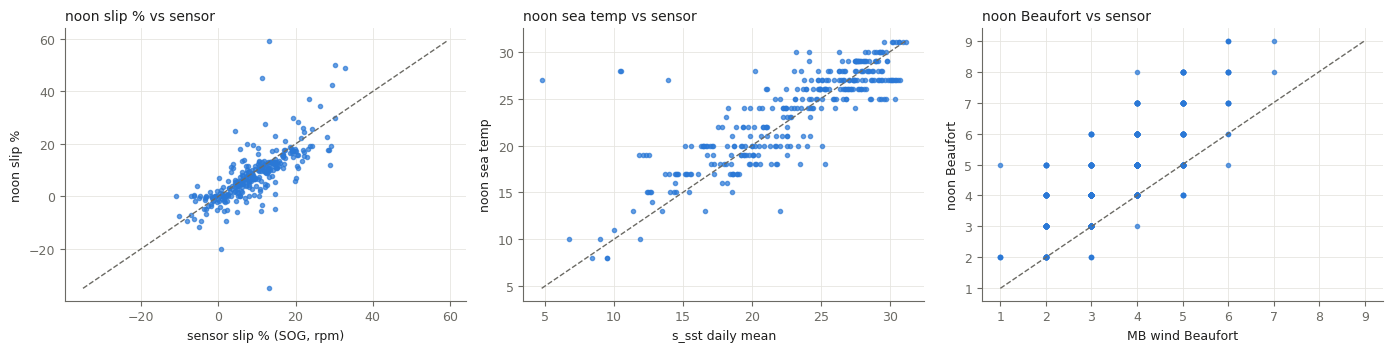

In [8]:
sail = (mode == "sailing") & (w.me_rpm > 50) & (w.sog_kn > 8)
slip_sog = (100 * (1 - w.sog_kn / (T.PITCH_M * w.me_rpm / 60 * T.KN))).where(sail)
sst = w.s_sst.where(~((w.s_sst.round(1) == 6.0)))
typo = noon["Sea Temp"] > 40
print("noon sea temperature above 40 °C (typos):", noon.loc[typo, "Sea Temp"].to_dict())
noon["sea_temp_clean"] = noon["Sea Temp"].where(~typo)
bf_edges = [0, 1, 3, 6, 10, 16, 21, 27, 33, 40, 47, 55, 63, 200]
cmp_ = pd.DataFrame({
    "noon slip %": noon.slip_pct, "sensor slip % (SOG, rpm)": T.daily(slip_sog, "median"),
    "noon sea temp": noon["sea_temp_clean"], "s_sst daily mean": sst.resample("D").mean(),
    "noon Beaufort": noon.beaufort,
    "MB wind Beaufort": pd.cut(w.mb_wind_kn.resample("D").mean(), bf_edges, labels=False, right=False),
})
out = []
for a_, b_ in [("noon slip %", "sensor slip % (SOG, rpm)"), ("noon sea temp", "s_sst daily mean"), ("noon Beaufort", "MB wind Beaufort")]:
    x = cmp_[[a_, b_]].dropna()
    out.append({"pair": f"{a_} vs {b_}", "days": len(x), "correlation": x.corr().iloc[0, 1], "median difference": (x[a_] - x[b_]).median(),
                "noon range": f"{x[a_].min():.0f} – {x[a_].max():.0f}"})
display(pd.DataFrame(out).set_index("pair").round(2))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (a_, b_) in zip(axes, [("noon slip %", "sensor slip % (SOG, rpm)"), ("noon sea temp", "s_sst daily mean"), ("noon Beaufort", "MB wind Beaufort")]):
    x = cmp_[[a_, b_]].dropna()
    ax.scatter(x[b_], x[a_], s=9, color=BLUE, alpha=0.7)
    lo, hi = np.nanmin(x.values), np.nanmax(x.values)
    ax.plot([lo, hi], [lo, hi], color=MUTED, ls="--", lw=1)
    ax.set_xlabel(b_); ax.set_ylabel(a_); ax.set_title(f"{a_} vs sensor", loc="left", color=INK)
fig.tight_layout(); plt.show()

## 5. Findings

In [9]:
F.add("Noon `Displacement`, drafts", "all year", "other",
      f"Reported displacement matches the mean draft through the hull particulars (median {e.median():+.1f} %, IQR {e.quantile(.25):+.1f} "
      f"to {e.quantile(.75):+.1f} %); drafts frozen while displacement changes on only {stale.sum()} days, all during cargo work in port",
      "§2", f"{(e.abs() > 10).sum()} days off by more than 10 %", "Noon loading condition is usable as the replacement for the dead draft sensors (DQ-01)",
      "Use noon displacement/drafts; flag the outlier days")
F.add("Noon `Consumption for Propulsion` vs `fo_kgh`", "all year", "other",
      f"Noon fuel follows the fuel meter all year (meter/noon {fuel_tab.iloc[0, 0]:.2f}, {fuel_tab.iloc[1, 0]:.2f}, {fuel_tab.iloc[2, 0]:.2f}; "
      f"correlation {scan.correlation.max():.2f}, noon-to-noon day ending ≈{24 + best:02d}:00 UTC), even after mid-October when two air-side "
      f"estimates show the meter shifting {shift:+.0f} %. Noon fuel is therefore most likely derived from the meter, not measured independently",
      "§3, §3b", f"{len(fd)} days compared", "Cannot be used to validate the fuel meter",
      "Use the air side (scavenge pressure, turbocharger speed) as the independent reference")
F.add("`fo_kgh` (confirms DQ-18)", "from 16 Oct 2024", "drift or bias",
      f"At the same load (2.5–3.5 MW band) fuel-based power rises {shift:+.0f} % against turbocharger-based power from mid-October, while "
      "scavenge-based and turbocharger-based power agree all year. The fuel meter reads high from mid-October",
      "§3b", "all fuel readings after 16 Oct", "Fuel-based power or fuel-based fouling indicators show fake fouling after October",
      "Use scavenge- or turbocharger-based virtual power; don't use fuel after 16 Oct without a correction")
F.add("Noon `Slip`", "all year", "other",
      f"Noon slip correlates {out[0]['correlation']:.2f} with apparent slip from GPS speed and engine rpm (median difference "
      f"{out[0]['median difference']:+.1f} points), but has extreme values ({noon.slip_pct.min():.0f} to {noon.slip_pct.max():.0f} %; "
      "physical apparent slip is about 0–20 %) and reads 0 on port days",
      "§4", f"{((noon.slip_pct < -10) | (noon.slip_pct > 30)).sum()} days outside −10 to 30 %", "Small; usable as a cross-check",
      "Prefer slip computed from sensors; ignore noon values outside −10 to 30 %")
F.add("Noon `Sea Temp`", ", ".join(str(d_.date()) for d_ in noon.index[typo]), "out of range",
      f"Typo: {', '.join(f'{v_:.0f} °C' for v_ in noon.loc[typo, 'Sea Temp'])} (probably a missing decimal point). Without it, noon sea temperature "
      f"correlates {out[1]['correlation']:.2f} with Provider S", "§4", f"{int(typo.sum())} day", "Small", "Set to NaN")
if len(at_sea):
    F.add("Noon `Displacement`", ", ".join(str(d_.date()) for d_ in at_sea.index), "timestamp",
          f"Displacement changes by more than 3,000 t on {len(at_sea)} days when the sensors show the ship at sea the whole day and the day before. "
          "Cargo cannot change at sea, so these are late or early reports (the change belongs to a nearby port call)",
          "§2b", f"{len(at_sea)} days", "Wrong laden/ballast label for a day or two around port calls",
          "Shift the loading change to the nearest port stay, or ignore the first sailing day after a port call")
F.table()

,signal,period,type,what,evidence,affected,impact,options
0,"Noon `Displacement`, drafts",all year,other,Reported displacement matches the mean draft t...,04_noon_reports §2,4 days off by more than 10 %,Noon loading condition is usable as the replac...,Use noon displacement/drafts; flag the outlier...
1,Noon `Consumption for Propulsion` vs `fo_kgh`,all year,other,Noon fuel follows the fuel meter all year (met...,"04_noon_reports §3, §3b",223 days compared,Cannot be used to validate the fuel meter,"Use the air side (scavenge pressure, turbochar..."
2,`fo_kgh` (confirms DQ-18),from 16 Oct 2024,drift or bias,At the same load (2.5–3.5 MW band) fuel-based ...,04_noon_reports §3b,all fuel readings after 16 Oct,Fuel-based power or fuel-based fouling indicat...,Use scavenge- or turbocharger-based virtual po...
3,Noon `Slip`,all year,other,Noon slip correlates 0.73 with apparent slip f...,04_noon_reports §4,16 days outside −10 to 30 %,Small; usable as a cross-check,Prefer slip computed from sensors; ignore noon...
4,Noon `Sea Temp`,2024-03-08,out of range,Typo: 214 °C (probably a missing decimal point...,04_noon_reports §4,1 day,Small,Set to NaN
5,Noon `Displacement`,2024-10-05,timestamp,"Displacement changes by more than 3,000 t on 1...",04_noon_reports §2b,1 days,Wrong laden/ballast label for a day or two aro...,Shift the loading change to the nearest port s...


In [10]:
print(F.markdown_rows(first_id=26))

| DQ-26 | Noon `Displacement`, drafts | all year | other | Reported displacement matches the mean draft through the hull particulars (median -1.5 %, IQR -2.1 to -0.1 %); drafts frozen while displacement changes on only 3 days, all during cargo work in port | 04_noon_reports §2 | 4 days off by more than 10 % | Noon loading condition is usable as the replacement for the dead draft sensors (DQ-01) | Use noon displacement/drafts; flag the outlier days | | open | mp, 28 Oct |
| DQ-27 | Noon `Consumption for Propulsion` vs `fo_kgh` | all year | other | Noon fuel follows the fuel meter all year (meter/noon 1.01, 1.05, 1.02; correlation 0.81, noon-to-noon day ending ≈09:00 UTC), even after mid-October when two air-side estimates show the meter shifting +16 %. Noon fuel is therefore most likely derived from the meter, not measured independently | 04_noon_reports §3, §3b | 223 days compared | Cannot be used to validate the fuel meter | Use the air side (scavenge pressure, turbocharger speed) as 

## Notes

Write your own observations here.